# Modelo M02: Estimación de Presión Arterial (Regresión)

**Curso:** Pruebas de Software (CI0142)  
**Etapa:** 2 - Desarrollo y Validación de Modelos  
**Problema:** Regresión supervisada para estimar la presión arterial sistólica ( en mmHg) basada en factores demográficos, clínicos y de estilo de vida.
**Métricas evaluadas:** MAE, MSE / RMSE, y Coeficiente de Determinación (^2$).

## 1. Importación de Librerías

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')
print('Librerías importadas correctamente.')

Librerías importadas correctamente.


## 2. Carga y Exploración Inicial del Conjunto de Datos

In [2]:
data_path = '../data/raw/m02_presion_arterial.csv'
df = pd.read_csv(data_path)
print(f'Dimensiones del dataset: {df.shape[0]} registros y {df.shape[1]} columnas.')
df.head()

Dimensiones del dataset: 4240 registros y 15 columnas.


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0


In [3]:
# Información de tipos y conteo de no-nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
dtypes: float64(9), int64(6)
memory usage: 497.0 KB


In [4]:
# Estadísticas descriptivas de las variables numéricas y objetivo (sysBP)
df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]

,count,mean,std,min,50%,max
male,4240.0,0.429245,0.495027,0.00,0.0,1.0
age,4240.0,49.580189,8.572942,32.00,49.0,70.0
education,4135.0,1.979444,1.019791,1.00,2.0,4.0
currentSmoker,4240.0,0.494104,0.500024,0.00,0.0,1.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.0,70.0
BPMeds,4187.0,0.029615,0.169544,0.00,0.0,1.0
prevalentStroke,4240.0,0.005896,0.076569,0.00,0.0,1.0
prevalentHyp,4240.0,0.310613,0.462799,0.00,0.0,1.0
diabetes,4240.0,0.025708,0.158280,0.00,0.0,1.0
totChol,4190.0,236.699523,44.591284,107.00,234.0,696.0


## 3. Limpieza y Tratamiento de Datos

Se inspeccionan los valores nulos:
1. Para personas no fumadoras (), si  es nulo, se imputa con 0.
2. Para variables continuas (, , , ), se utiliza la mediana para evitar distorsiones por valores extremos.
3. Para variables categóricas o binarias (, ), se imputa la moda (valor más frecuente).

In [5]:
# Inspección de nulos iniciales
null_counts = df.isna().sum()
print('Valores faltantes por columna:')
print(null_counts[null_counts > 0])

Valores faltantes por columna:
education     105
cigsPerDay     29
BPMeds         53
totChol        50
BMI            19
heartRate       1
glucose       388
dtype: int64


In [6]:
# Limpieza condicional de cigsPerDay
df.loc[(df['currentSmoker'] == 0) & (df['cigsPerDay'].isna()), 'cigsPerDay'] = 0

feature_cols = [
    'male', 'age', 'education', 'currentSmoker', 'cigsPerDay',
    'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes',
    'totChol', 'BMI', 'heartRate', 'glucose'
]
target_col = 'sysBP'

X = df[feature_cols]
y = df[target_col]
print(f'Total de características predictoras: {len(feature_cols)}')

Total de características predictoras: 13


## 4. División de Datos (Entrenamiento y Prueba)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Conjunto de entrenamiento: {X_train.shape[0]} muestras')
print(f'Conjunto de prueba: {X_test.shape[0]} muestras')

Conjunto de entrenamiento: 3392 muestras
Conjunto de prueba: 848 muestras


## 5. Construcción del Pipeline y Entrenamiento de Modelos

Se evalúan 6 modelos según los lineamientos del curso:
* **DummyRegressor (Mean)** como línea base obligatoria.
* **Linear Regression** y **Ridge Regression** (modelos paramétricos).
* **Decision Tree Regressor**, **Random Forest** y **Gradient Boosting** (modelos de ensamblaje no lineales).

In [8]:
numerical_cols = ['age', 'education', 'cigsPerDay', 'totChol', 'BMI', 'heartRate', 'glucose']
binary_cols = ['male', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes']

def create_pipeline(model):
    num_trans = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    bin_trans = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent'))
    ])
    pre = ColumnTransformer([
        ('num', num_trans, numerical_cols),
        ('bin', bin_trans, binary_cols)
    ])
    return Pipeline([('preprocessor', pre), ('regressor', model)])

candidate_models = {
    'Dummy (Mean)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42)
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []
trained_pipes = {}

for name, model in candidate_models.items():
    pipe = create_pipeline(model)
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=kf, scoring='r2').mean()
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    results.append({
        'Modelo': name,
        'CV R2 (5-fold)': cv_r2,
        'MAE (mmHg)': mae,
        'RMSE (mmHg)': rmse,
        'R2 Test': r2
    })
    trained_pipes[name] = pipe

res_df = pd.DataFrame(results).sort_values('RMSE (mmHg)')
res_df

,Modelo,CV R2 (5-fold),MAE (mmHg),RMSE (mmHg),R2 Test
2,Ridge Regression,0.549622,10.811435,14.393570,0.532132
1,Linear Regression,0.549581,10.814074,14.395030,0.532037
5,Gradient Boosting,0.552502,10.861065,14.463496,0.527575
4,Random Forest,0.546377,10.982527,14.482856,0.526310
3,Decision Tree,0.507522,11.290586,14.776916,0.506879
0,Dummy (Mean),-0.002543,16.051653,21.050368,-0.000704


## 6. Visualización y Comparación de Métricas

/tmp/ipykernel_264997/4188961239.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_df, x='RMSE (mmHg)', y='Modelo', ax=axes[0], palette='viridis')
/tmp/ipykernel_264997/4188961239.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_df, x='R2 Test', y='Modelo', ax=axes[1], palette='magma')


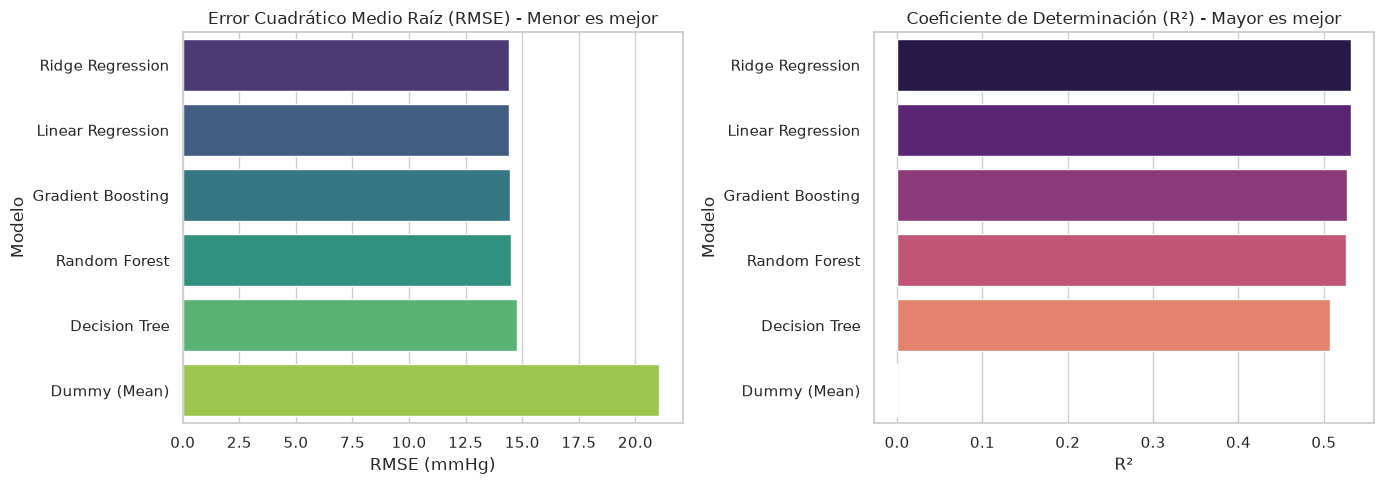

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=res_df, x='RMSE (mmHg)', y='Modelo', ax=axes[0], palette='viridis')
axes[0].set_title('Error Cuadrático Medio Raíz (RMSE) - Menor es mejor')
axes[0].set_xlabel('RMSE (mmHg)')

sns.barplot(data=res_df, x='R2 Test', y='Modelo', ax=axes[1], palette='magma')
axes[1].set_title('Coeficiente de Determinación (R²) - Mayor es mejor')
axes[1].set_xlabel('R²')

plt.tight_layout()
plt.show()

## 7. Exportación del Modelo Ganador para Uso en el API

Se exporta el artefacto serializado con  para ser consumido por el backend del proyecto.

In [10]:
best_name = res_df.iloc[0]['Modelo']
best_pipe = trained_pipes[best_name]

models_dir = '../models'
os.makedirs(models_dir, exist_ok=True)
export_file = os.path.join(models_dir, 'm02_presion_arterial.joblib')

artifact = {
    'model_id': 'M02',
    'description': 'Estimacion de Presion Arterial Sistolica (sysBP)',
    'model_name': best_name,
    'pipeline': best_pipe,
    'feature_names': feature_cols,
    'metrics': res_df.iloc[0].to_dict()
}
joblib.dump(artifact, export_file)
print(f'Modelo {best_name} guardado con éxito en: {export_file}')

Modelo Ridge Regression guardado con éxito en: ../models/m02_presion_arterial.joblib


## 8. Verificación de Inferencia y Límites (Pruebas)

In [11]:
# Caso 1: Paciente normotenso promedio
patient_normal = pd.DataFrame([{
    'male': 0, 'age': 35, 'education': 2, 'currentSmoker': 0, 'cigsPerDay': 0,
    'BPMeds': 0, 'prevalentStroke': 0, 'prevalentHyp': 0, 'diabetes': 0,
    'totChol': 190, 'BMI': 22.5, 'heartRate': 70, 'glucose': 80
}])

# Caso 2: Paciente de alto riesgo con antecedentes de hipertensión y edad avanzada
patient_risk = pd.DataFrame([{
    'male': 1, 'age': 65, 'education': 1, 'currentSmoker': 1, 'cigsPerDay': 30,
    'BPMeds': 1, 'prevalentStroke': 1, 'prevalentHyp': 1, 'diabetes': 1,
    'totChol': 310, 'BMI': 34.0, 'heartRate': 95, 'glucose': 150
}])

pred_normal = best_pipe.predict(patient_normal)[0]
pred_risk = best_pipe.predict(patient_risk)[0]

print(f'Predicción paciente normotenso: {pred_normal:.2f} mmHg')
print(f'Predicción paciente alto riesgo:  {pred_risk:.2f} mmHg')

Predicción paciente normotenso: 113.74 mmHg
Predicción paciente alto riesgo:  177.08 mmHg
